# TP 3 – Boosting: AdaBoost and gradient boosting – Solutions

Bagging (TP 2) averages strong, unstable learners trained independently; boosting builds a *weighted* vote of weak learners trained *sequentially*, each one focusing on the errors of the previous ones. In this session we implement AdaBoost with decision stumps and gradient boosting with regression trees, and we start to *prove* things: short derivations explain why AdaBoost's weights have their form and why its training error decreases exponentially fast. We then compare all the methods seen so far on real data, and we end by looking at the vote of AdaBoost as a *weighted* majority vote, with the margins and the quantities of Part IV of the lecture notes.

**Data.** `wdbc`, `pima`, `australian` and `spambase` ($4597$ e-mails, $57$ features) loaded with `load(name)` of `common/tptools.py`, labels in $\{-1,+1\}$, and the `diabetes` regression dataset of `scikit-learn`. The file `tp3_starter.py` contains the skeletons.

> **Good practice.** Boosting runs hundreds of rounds, and each round learns a base classifier: anything that does not change from one round to the next (here, the sort of each feature) must be computed once, before the loop. Store the scores $f_t(x)=\sum_{s\leq t}\alpha_sh_s(x)$ of every round to plot the curves without recomputing anything.

## Setup

In [1]:
import os, sys, time, warnings
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (AdaBoostClassifier, RandomForestClassifier, GradientBoostingClassifier,
                              GradientBoostingRegressor)
from sklearn.datasets import load_diabetes
warnings.filterwarnings("ignore")

HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
sys.path.insert(0, os.path.join(HERE, "..", "common"))
from tptools import load, show_table as _show_rows

C1, C2, C3, C4, C5, GREY = "#1f5f99", "#c8553d", "#2a9d8f", "#e9a13b", "#6c4f9c", "#8c8c8c"
plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
                     "savefig.bbox": "tight"})


plt.rcParams["figure.dpi"] = 120

# column headers of the tables
HEADERS = {
    'p1_check': ['weights', 'error (ours)', 'error (brute force)', 'feature (ours)', 'feature (brute force)'],
    'p2_adaboost': ['data', '$t=1$ – test', '$t=10$ – train', '$t=10$ – test', '$t=100$ – train', '$t=100$ – test', '$t=500$ – train', '$t=500$ – test', 'sklearn – test', 'agreement'],
    'p2_eps': ['$t$', '1', '2', '3', '10', '50', '100', '500'],
    'p4_gb': ['$\\nu$', 'selected $M$', 'training MSE', 'validation MSE', 'test MSE', 'test MSE ($M=1000$)', 'difference with sklearn'],
    'p5_compare': ['method', '`wdbc`', '`pima`', '`australian`', '`spambase`'],
    'p6_vote': ['vote', '$t$', 'risk of the vote', 'Gibbs risk', 'joint error $\\hat e(Q)$', '$2\\widehat{R}(G_Q)$', '$4\\hat e(Q)$'],
    'p6_margins': ['$t$', 'training error', 'smallest margin', 'margins $\\leq0.1$', 'test error'],
    'p6_noise': ['training noise', 'AdaBoost $t=100$', 'AdaBoost best $t^\\ast$', 'AdaBoost $t=1000$', 'random forest'],
}


TABLES, FIGURES = {}, {}


def keep_table(name, rows):
    """Keep the rows of a table ('a & b & c', math between $) to show it later with show_table(name)."""
    TABLES[name] = rows


def keep_figure(fig, name):
    """Keep a figure to show it later with show_figure(name)."""
    FIGURES[name] = fig
    plt.close(fig)


def show_table(name):
    _show_rows(TABLES[name], HEADERS.get(name))


def show_figure(name):
    from IPython.display import display
    display(FIGURES[name])

## Part 1: Decision stumps on weighted data

A decision stump is a tree of depth one: $h_{j,t,s}(x)=s\cdot\operatorname{sign}(x_j-t)$, with a feature $j$, a threshold $t$ and a sign $s\in\{-1,+1\}$. Given nonnegative weights $w_1,\dots,w_m$ summing to $1$, its weighted error is $\varepsilon_w(h)=\sum_{i=1}^mw_i\mathbb{1}\left[h(x_i)\neq y_i\right]$.

1.  Let the examples be sorted by $x_j$, and let $L_k=\sum_{i\leq k}w_iy_i$ (sum over the $k$ first sorted examples) and $W=\sum_iw_iy_i$.\
    Show that the stump with sign $s=+1$ cutting after the $k$-th example has weighted error $\frac12-\frac12(W-2L_k)$, and that the stump with $s=-1$ has error $1$ minus this quantity.

2.  Write a class `Stumps(X)` which sorts every feature once in its constructor, and a method `fit(y, w)` which returns the best stump with no loop over the examples (use `np.cumsum`).

3.  Check your method against a brute-force search (loops over $j$, $t$ and $s$) on $150$ examples of `pima`, with uniform and with random weights.\
    How long do $100$ calls take on `spambase`?

In [2]:
class Stumps:
    """Weighted decision stumps h(x) = s * sign(x_j - t) (s in {-1,+1}), for a fixed training set.
    The sort of each feature is computed once, so that each call to fit costs O(d m)."""

    def __init__(self, X):
        self.X = X; m, d = X.shape
        self.order = np.argsort(X, axis=0, kind="mergesort")
        self.xs = np.take_along_axis(X, self.order, 0)
        xs = self.xs
        # thresholds: below the smallest value, then midpoints between consecutive distinct values
        self.thr = np.vstack([xs[:1] - 1, 0.5 * (xs[1:] + xs[:-1])])
        self.valid = np.vstack([np.ones((1, d), bool), xs[1:] > xs[:-1]])

    def fit(self, y, w):
        """Return (weighted error, j, t, s) of the best stump. w: nonnegative weights summing to 1."""
        wy = (w * y)[self.order]                                   # sorted by each feature, shape (m, d)
        # cut k (k = 0..m-1) puts the k first sorted points on the left (predicted -s), the others on the right (+s)
        left = np.vstack([np.zeros((1, wy.shape[1])), np.cumsum(wy, 0)[:-1]])   # sum of w*y on the left
        total = wy.sum(0)
        # error of s=+1: positives on the left + negatives on the right = (W - sum_right w y - ... ) simplified:
        # err(+1) = 1/2 - (total - 2 left) / 2 ; err(-1) = 1 - err(+1)
        err_pos = 0.5 - 0.5 * (total[None, :] - 2 * left)
        err_pos = np.where(self.valid, err_pos, np.inf)
        err_neg = np.where(self.valid, 1 - err_pos, np.inf)
        i1, j1 = np.unravel_index(np.argmin(err_pos), err_pos.shape)
        i2, j2 = np.unravel_index(np.argmin(err_neg), err_neg.shape)
        if err_pos[i1, j1] <= err_neg[i2, j2]:
            return err_pos[i1, j1], j1, self.thr[i1, j1], 1
        return err_neg[i2, j2], j2, self.thr[i2, j2], -1


def stump_predict(X, j, t, s):
    return s * np.where(X[:, j] > t, 1, -1)


def brute_force_stump(X, y, w):
    best = (np.inf, None, None, None)
    for j in range(X.shape[1]):
        vals = np.unique(X[:, j]); ts = np.r_[vals[0] - 1, 0.5 * (vals[1:] + vals[:-1])]
        for t in ts:
            for s in (1, -1):
                e = np.sum(w * (stump_predict(X, j, t, s) != y))
                if e < best[0] - 1e-12:
                    best = (e, j, t, s)
    return best


def part1():
    print("Part 1")
    X, y = load("pima"); rng = np.random.RandomState(0); rows = []
    for trial in range(3):
        idx = rng.choice(len(y), 150, replace=False); Xs, ys = X[idx], y[idx]
        w = rng.rand(150) if trial else np.ones(150); w /= w.sum()
        a = Stumps(Xs).fit(ys, w); b = brute_force_stump(Xs, ys, w)
        rows.append(f"{'uniform' if trial == 0 else 'random'} & {a[0]:.4f} & {b[0]:.4f} & {int(a[1])} & {int(b[1])}")
    keep_table("p1_check", rows)
    X, ys = load("spambase"); t0 = time.time(); S = Stumps(X)
    w = np.ones(len(ys)) / len(ys); t1 = time.time()
    for _ in range(100):
        S.fit(ys, w)
    print(f"   spambase: sort {t1 - t0:.2f}s, 100 fits {time.time() - t1:.2f}s")

In [3]:
part1()

Part 1
   spambase: sort 0.02s, 100 fits 0.31s


### Solution

**1.** The stump with $s=+1$ predicts $-1$ on the $k$ first examples and $+1$ on the others; it errs on the positive examples on the left and on the negative examples on the right. Since $w_i\mathbb{1}\left[y_i=1\right]=\frac{w_i(1+y_i)}2$ and $w_i\mathbb{1}\left[y_i=-1\right]=\frac{w_i(1-y_i)}2$, $$\begin{aligned}
\varepsilon&=\sum_{i\leq k}\frac{w_i(1+y_i)}{2}+\sum_{i>k}\frac{w_i(1-y_i)}{2}=\frac12\sum_iw_i+\frac12L_k-\frac12(W-L_k)\\
&=\frac12-\frac12(W-2L_k).
\end{aligned}$$ The stump with $s=-1$ predicts the opposite label everywhere, so it errs exactly where the first one is right. Cuts between two equal values of $x_j$ are not allowed; $k=0$ (threshold below all the values) gives the constant classifiers.

**2--3.** Our method and the brute-force search find the same weighted error and the same feature:

In [4]:
show_table("p1_check")

| weights | error (ours) | error (brute force) | feature (ours) | feature (brute force) |
|:---:|:---:|:---:|:---:|:---:|
| uniform | 0.2133 | 0.2133 | 1 | 1 |
| random | 0.2044 | 0.2044 | 1 | 1 |
| random | 0.2597 | 0.2597 | 7 | 7 |

On the $4597$ examples of `spambase`, sorting the $57$ features takes a few hundredths of a second once, and each call to `fit` then takes about $4$ ms: $500$ rounds of AdaBoost cost a few seconds. Note that `DecisionTreeClassifier(max_depth=1)` minimizes the weighted *Gini impurity*, not the weighted error: it may choose a different stump.

## Part 2: AdaBoost from scratch (Section 10.2)

1.  Implement AdaBoost (Algorithm AdaBoost of Section 10.2) with your stumps: at round $t$, learn the stump $h_t$ minimizing the weighted error $\varepsilon_t$, set $\alpha_t=\frac12\ln\frac{1-\varepsilon_t}{\varepsilon_t}$, update $w_i\leftarrow w_ie^{-\alpha_ty_ih_t(x_i)}/Z_t$, and return $H_T=\operatorname{sign}(f_T)$ with $f_T=\sum_{t\leq T}\alpha_th_t$.\
    Store $\varepsilon_t$, $\alpha_t$, $Z_t$ and the scores $f_t$ on the training and test sets.

2.  On `wdbc` and `spambase` ($70\%/30\%$), run $T=500$ rounds and plot, against $t$ (log scales), the training error, the test error, $\prod_{s\leq t}Z_s$ and $\exp\big(-2\sum_{s\leq t}(\frac12-\varepsilon_s)^2\big)$.

3.  How do $\varepsilon_t$ and $\alpha_t$ evolve with $t$?\
    Why?

4.  Compare with `AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=500)`.

5.  What happens to the test error once the training error is $0$?\
    Is this what you expected after TP 1 (overfitting) and TP 2 (number of trees in bagging)?

In [5]:
def adaboost(Xtr, ytr, T, Xev=()):
    """AdaBoost with decision stumps. Returns the stumps, their weights alpha, the weighted errors eps,
    the normalisation factors Z, and the scores f_t(x) = sum_{s<=t} alpha_s h_s(x) on the training set and on
    each array of Xev, for t = 1..T (arrays of shape (T, n))."""
    m = len(ytr); w = np.ones(m) / m; S = Stumps(Xtr)
    stumps, alpha, eps, Z, check = [], [], [], [], []
    ftr = np.zeros(m); fev = [np.zeros(len(X)) for X in Xev]; Ftr = []; Fev = [[] for _ in Xev]
    for t in range(T):
        e, j, thr, s = S.fit(ytr, w)
        e = min(max(e, 1e-10), 1 - 1e-10)
        a = 0.5 * np.log((1 - e) / e)
        h = stump_predict(Xtr, j, thr, s)
        w = w * np.exp(-a * ytr * h); z = w.sum(); w = w / z
        check.append(abs(np.sum(w * (h != ytr)) - 0.5))           # weighted error of h_t under w^(t+1)
        stumps.append((j, thr, s)); alpha.append(a); eps.append(e); Z.append(z)
        ftr = ftr + a * h; Ftr.append(ftr.copy())
        for k, X in enumerate(Xev):
            fev[k] = fev[k] + a * stump_predict(X, j, thr, s); Fev[k].append(fev[k].copy())
    return dict(stumps=stumps, alpha=np.array(alpha), eps=np.array(eps), Z=np.array(Z), check=np.array(check),
                Ftr=np.array(Ftr), Fev=[np.array(F) for F in Fev])


def err(F, y):
    """Errors of sign(F_t) for all t (ties count as errors)."""
    return np.mean(np.where(F > 0, 1, -1) != y[None, :], axis=1)


def part2():
    print("Part 2")
    T = 500; rows = []; res = {}
    for name in ["wdbc", "spambase"]:
        X, y = load(name)
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
        A = adaboost(Xtr, ytr, T, (Xte,))
        tr, te = err(A["Ftr"], ytr), err(A["Fev"][0], yte)
        prodZ = np.cumprod(A["Z"]); expb = np.exp(-2 * np.cumsum((0.5 - A["eps"]) ** 2))
        stump = DecisionTreeClassifier(max_depth=1)
        sk = AdaBoostClassifier(stump, n_estimators=T, random_state=0).fit(Xtr, ytr)
        agree = np.mean(sk.predict(Xte) == np.where(A["Fev"][0][-1] > 0, 1, -1))
        res[name] = (tr, te, prodZ, expb, A)
        rows.append(f"{name} & {te[0]:.3f} & {tr[9]:.3f} & {te[9]:.3f} & {tr[99]:.3f} & {te[99]:.3f} & {tr[-1]:.3f} & {te[-1]:.3f} & "
                    f"{np.mean(sk.predict(Xte) != yte):.3f} & {agree:.3f}")
        print("  ", name + ": max |eps' - 1/2| =", A["check"].max(), "first t with zero training error:",
              int(np.argmax(tr == 0)) + 1 if (tr == 0).any() else None)
    keep_table("p2_adaboost", rows)
    fig, axes = plt.subplots(1, 2, figsize=(7.4, 2.6))
    for ax, (name, (tr, te, pz, eb, A)) in zip(axes, res.items()):
        t = np.arange(1, T + 1)
        ax.plot(t, tr, color=C1, label="training error"); ax.plot(t, te, color=C2, label="test error")
        ax.plot(t, pz, color=C4, ls="--", lw=1, label=r"$\prod_{s\leq t}Z_s$")
        ax.plot(t, eb, color=GREY, ls=":", lw=1, label=r"$\exp(-2\sum_{s\leq t}(1/2-\varepsilon_s)^2)$")
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-3, 1.2); ax.set_xlabel("number of rounds $t$")
        ax.set_title(name, fontsize=9)
    axes[0].legend(fontsize=7)
    fig.tight_layout(); keep_figure(fig, "tp3_adaboost")
    # weighted errors along the rounds (spambase)
    A = res["spambase"][4]
    keep_table("p2_eps", ["$\\varepsilon_t$ & " + " & ".join(f"{A['eps'][t]:.3f}" for t in [0, 1, 2, 9, 49, 99, 499]) + "",
                            "$\\alpha_t$ & " + " & ".join(f"{A['alpha'][t]:.3f}" for t in [0, 1, 2, 9, 49, 99, 499]) + ""])
    return res

In [6]:
res = part2()

Part 2
   wdbc: max |eps' - 1/2| = 1.4432899320127035e-15 first t with zero training error: 15
   spambase: max |eps' - 1/2| = 9.325873406851315e-15 first t with zero training error: None


### Solution

**1--2, 4.** Errors after $1$, $10$, $100$ and $500$ rounds, test error of `scikit-learn` and agreement of the two final classifiers on the test set:

In [7]:
show_table("p2_adaboost")

| data | $t=1$ – test | $t=10$ – train | $t=10$ – test | $t=100$ – train | $t=100$ – test | $t=500$ – train | $t=500$ – test | sklearn – test | agreement |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| wdbc | 0.140 | 0.010 | 0.082 | 0.000 | 0.041 | 0.000 | 0.047 | 0.053 | 0.982 |
| spambase | 0.204 | 0.089 | 0.104 | 0.049 | 0.061 | 0.036 | 0.062 | 0.057 | 0.957 |

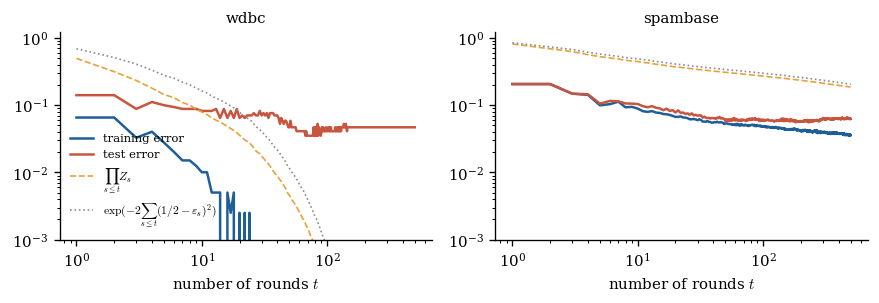

In [8]:
show_figure("tp3_adaboost")

A single stump has a test error of $0.14$ on `wdbc` and $0.20$ on `spambase`; the vote of $500$ stumps reaches $0.05$ and $0.06$. The training error always lies below $\prod_sZ_s$, itself below $\exp(-2\sum_s(\frac12-\varepsilon_s)^2)$ (Part 3): on `wdbc` it first reaches $0$ after $15$ rounds and stays at $0$ from round $25$ on. Our implementation and `scikit-learn`'s agree on $97$--$99\%$ of the test points; the differences come from the choice of the stump (`scikit-learn` minimizes the weighted Gini impurity) and `scikit-learn` uses $\alpha_t=\ln\frac{1-\varepsilon_t}{\varepsilon_t}$ (algorithm SAMME), twice ours, which gives the same vote.

**3.** On `spambase`, at rounds $1,2,3,10,50,100,500$:

In [9]:
show_table("p2_eps")

| $t$ | 1 | 2 | 3 | 10 | 50 | 100 | 500 |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| $\varepsilon_t$ | 0.206 | 0.234 | 0.291 | 0.398 | 0.463 | 0.467 | 0.483 |
| $\alpha_t$ | 0.675 | 0.593 | 0.444 | 0.206 | 0.074 | 0.066 | 0.035 |

The weighted error increases towards $\frac12$ and $\alpha_t$ decreases towards $0$: the weights concentrate on the examples that are hard to classify, for which no stump is much better than chance. The first stumps receive a large weight, the late ones only make small corrections.

**5.** On `wdbc` the training error first reaches $0$ at $t=15$ and stays at $0$ from $t=25$ on (test error $0.070$), but the test error keeps decreasing afterwards ($0.041$ at $t=100$) and then stabilizes (the curve fluctuates by one or two test errors out of $171$). This seems to contradict the idea that a more complex model (here a vote of more stumps) overfits. The explanation is in Part 6: after the training error is $0$, AdaBoost keeps increasing the *margins* of the training examples, i.e. the confidence of the vote.

## Part 3: Why AdaBoost works: three short proofs

Let $w=w^{(t)}$ be the weights at round $t$, $h=h_t$, $\varepsilon=\varepsilon_t\in(0,\frac12)$ and, for $\alpha\in\mathbb{R}$, $Z(\alpha)=\sum_iw_ie^{-\alpha y_ih(x_i)}$.

1.  Show that $Z(\alpha)=(1-\varepsilon)e^{-\alpha}+\varepsilon e^{\alpha}$, that it is minimized by $\alpha_t=\frac12\ln\frac{1-\varepsilon}{\varepsilon}$, and that $Z(\alpha_t)=2\sqrt{\varepsilon(1-\varepsilon)}$.

2.  Show that the weighted error of $h_t$ under the *new* weights $w^{(t+1)}$ is exactly $\frac12$.\
    Check it numerically.\
    What does this imply for $h_{t+1}$?

3.  Show that $w^{(T+1)}_i=\frac{e^{-y_if_T(x_i)}}{m\prod_{t\leq T}Z_t}$, and deduce, using $\mathbb{1}\left[yf(x)\leq 0\right]\leq e^{-yf(x)}$, that the training error satisfies $\widehat{R}_{S}(H_T)\leq\prod_{t\leq T}Z_t$.\
    Then use $1-x\leq e^{-x}$ to obtain the bound of Section 10.2, $\widehat{R}_{S}(H_T)\leq\exp\big(-2\sum_t(\frac12-\varepsilon_t)^2\big)$.

### Solution

**1.** $y_ih(x_i)=1$ on the correctly classified examples (total weight $1-\varepsilon$) and $-1$ on the others (weight $\varepsilon$), hence $Z(\alpha)=(1-\varepsilon)e^{-\alpha}+\varepsilon e^{\alpha}$. It is convex, and $Z'(\alpha)=-(1-\varepsilon)e^{-\alpha}+\varepsilon e^\alpha=0\iff e^{2\alpha}=\frac{1-\varepsilon}{\varepsilon}$. At this point $e^{-\alpha_t}=\sqrt{\varepsilon/(1-\varepsilon)}$ and $Z(\alpha_t)=2\sqrt{\varepsilon(1-\varepsilon)}$, which is $<1$ as soon as $\varepsilon\neq\frac12$. AdaBoost thus chooses $\alpha_t$ to decrease the normalisation factor as much as possible, i.e. (question 3) the training exponential loss.

**2.** The new weight of the misclassified examples is $\sum_{i:\,h(x_i)\neq y_i}w_ie^{\alpha_t}/Z_t=\varepsilon\sqrt{\frac{1-\varepsilon}{\varepsilon}}\big/2\sqrt{\varepsilon(1-\varepsilon)}=\frac12$. Numerically, $|\varepsilon^{(t+1)}(h_t)-\frac12|<10^{-14}$ at every round. So $h_t$ is no better than chance for the new weights: the next stump is forced to be different and to do better on the examples $h_t$ misclassified. (It can be chosen again later.)

**3.** By induction, $w^{(t+1)}_i=w^{(t)}_ie^{-\alpha_ty_ih_t(x_i)}/Z_t$ and $w^{(1)}_i=\frac1m$ give $w^{(T+1)}_i=\frac1m\prod_te^{-\alpha_ty_ih_t(x_i)}/Z_t=\frac{e^{-y_if_T(x_i)}}{m\prod_tZ_t}$. Since the weights sum to $1$, $$\widehat{R}_{S}(H_T)=\frac1m\sum_i\mathbb{1}\left[y_if_T(x_i)\leq 0\right]\leq\frac1m\sum_ie^{-y_if_T(x_i)}=\prod_tZ_t\sum_iw^{(T+1)}_i=\prod_tZ_t.$$ Finally, with $\gamma_t=\frac12-\varepsilon_t$, $Z_t=2\sqrt{(\frac12-\gamma_t)(\frac12+\gamma_t)}=\sqrt{1-4\gamma_t^2}
\leq\sqrt{e^{-4\gamma_t^2}}=e^{-2\gamma_t^2}$. If every stump has an edge $\gamma_t\geq\gamma>0$, the training error is below $e^{-2\gamma^2T}$, hence $0$ as soon as $T>\frac{\ln m}{2\gamma^2}$. This is a statement on the *training* error only: it says nothing about the true risk, which requires the generalization bounds of TP 1, 4 and 5.

## Part 4: Gradient boosting for regression (Section 10.3)

Gradient boosting builds $F_M(x)=F_0+\nu\sum_{k=1}^Mg_k(x)$, where $F_0=\bar y$ and each $g_k$ is a small regression tree fitted to the *negative gradient* of the loss at the current predictions; $\nu\in(0,1]$ is the learning rate (shrinkage).

1.  For the squared loss $\ell(y,F)=\frac12(y-F)^2$, show that the negative gradient with respect to $F(x_i)$ is the residual $y_i-F_{k-1}(x_i)$.\
    Write the algorithm.

2.  Implement it with `DecisionTreeRegressor(max_depth=2)` as base learner.\
    On `diabetes`, split the data $60/20/20$ (training, validation, test).\
    For $\nu\in\{1,0.3,0.1,0.03\}$ and up to $M=1000$ trees, plot the training and validation MSE against $M$.

3.  For each $\nu$, select $M$ on the validation set (early stopping) and report the test MSE.\
    Compare with `GradientBoostingRegressor` with the same parameters (`criterion="squared_error"`).

4.  What is the role of $\nu$?\
    Why is boosting, unlike bagging, able to overfit when $M$ grows?

In [10]:
def gradient_boosting(Xtr, ytr, Xev, M, nu, depth=2):
    """Gradient boosting with the squared loss: F_0 = mean, then F_k = F_{k-1} + nu * tree fitted on the residuals."""
    F = np.full(len(ytr), ytr.mean()); G = [np.full(len(X), ytr.mean()) for X in Xev]
    hist_tr, hist_ev = [], [[] for _ in Xev]
    for k in range(M):
        r = ytr - F                                      # residuals = minus the gradient of (1/2)(y - F)^2
        tree = DecisionTreeRegressor(max_depth=depth, random_state=0).fit(Xtr, r)
        F = F + nu * tree.predict(Xtr); hist_tr.append(np.mean((ytr - F) ** 2))
        for i, X in enumerate(Xev):
            G[i] = G[i] + nu * tree.predict(X); hist_ev[i].append(G[i].copy())
    return np.array(hist_tr), [np.array(h) for h in hist_ev]


def part4():
    print("Part 4")
    X, y = load_diabetes(return_X_y=True)
    Xtr, Xr, ytr, yr = train_test_split(X, y, test_size=0.4, random_state=0)
    Xva, Xte, yva, yte = train_test_split(Xr, yr, test_size=0.5, random_state=0)
    M = 1000; rows = []; curves = {}
    for nu in [1.0, 0.3, 0.1, 0.03]:
        htr, (hva, hte) = gradient_boosting(Xtr, ytr, (Xva, Xte), M, nu)
        mva = np.mean((hva - yva[None, :]) ** 2, 1); mte = np.mean((hte - yte[None, :]) ** 2, 1)
        k = int(np.argmin(mva))
        sk = GradientBoostingRegressor(learning_rate=nu, n_estimators=k + 1, max_depth=2, criterion="squared_error",
                                       random_state=0).fit(Xtr, ytr)
        diff = np.max(np.abs(sk.predict(Xte) - hte[k]))
        curves[nu] = (htr, mva)
        rows.append(f"{nu:g} & {k + 1} & {htr[k]:.0f} & {mva[k]:.0f} & {mte[k]:.0f} & {mte[-1]:.0f} & {diff:.1e}")
    base = np.mean((yte - ytr.mean()) ** 2)
    rows.append(f"--- constant predictor (mean) & -- & -- & -- & {base:.0f} & -- & --")
    keep_table("p4_gb", rows)
    fig, ax = plt.subplots(figsize=(4.6, 2.6))
    for (nu, (htr, mva)), c in zip(curves.items(), [C2, C4, C1, C3]):
        k = np.arange(1, M + 1)
        ax.plot(k, htr, color=c, ls="--", lw=0.9); ax.plot(k, mva, color=c, label=fr"$\nu={nu:g}$")
    ax.set_xscale("log"); ax.set_xlabel("number of trees $M$"); ax.set_ylabel("MSE")
    ax.set_title("diabetes (solid: validation, dashed: training)", fontsize=9); ax.set_ylim(0, 6000); ax.legend(fontsize=7.5)
    fig.tight_layout(); keep_figure(fig, "tp3_gb")

In [11]:
part4()

Part 4


### Solution

**1.** $-\frac{\partial}{\partial F}\frac12(y_i-F)^2\big|_{F=F_{k-1}(x_i)}=y_i-F_{k-1}(x_i)$. Algorithm: $F_0=\bar y$; for $k=1,\dots,M$: compute the residuals $r_i=y_i-F_{k-1}(x_i)$, fit a regression tree $g_k$ to $\{(x_i,r_i)\}$, set $F_k=F_{k-1}+\nu g_k$. Each tree corrects what the current model has not explained yet; for another loss only the definition of $r_i$ changes.

**2--3.**

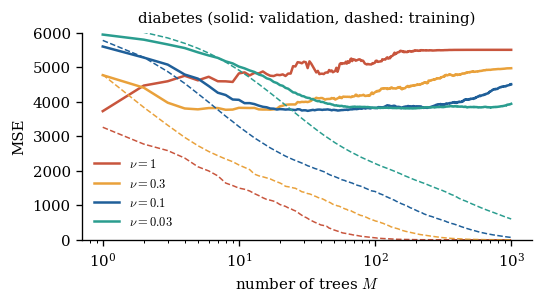

In [12]:
show_figure("tp3_gb")

In [13]:
show_table("p4_gb")

| $\nu$ | selected $M$ | training MSE | validation MSE | test MSE | test MSE ($M=1000$) | difference with sklearn |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| 1 | 1 | 3262 | 3728 | 3451 | 6271 | 0.0e+00 |
| 0.3 | 8 | 2340 | 3768 | 2813 | 5144 | 5.7e-14 |
| 0.1 | 32 | 2146 | 3737 | 2838 | 4593 | 2.8e-14 |
| 0.03 | 165 | 1859 | 3806 | 2949 | 3889 | 5.7e-14 |
| constant predictor (mean) | – | – | – | 4445 | – | – |

Our predictions coincide with those of `scikit-learn` up to rounding errors. With $\nu=1$ the validation error is minimal after a single tree and then grows quickly: each tree fits the residuals completely, including their noise. With a smaller $\nu$ the curves are smoother, more trees are needed ($8$, $32$, $165$), and the test error at the selected $M$ is lower ($2800$--$2950$ against $3450$ for $\nu=1$, and $4450$ for the constant predictor). Without early stopping ($M=1000$) every model overfits, all the more as $\nu$ is large.

**4.** $\nu$ is a regularization parameter: it slows down the fit so that many small, complementary steps are taken instead of a few greedy ones, at the price of more trees; $\nu$ and $M$ must be tuned together (in practice: small $\nu$, $M$ by early stopping). Bagging averages trees learned *independently* on the same problem: more trees only reduce the variance of the average. Boosting adds trees that *fit what remains*: the model becomes more and more complex, and its training error tends to $0$; $M$ is a complexity parameter, like the depth of a tree.

## Part 5: Comparing the methods of the course

1.  With $5$-fold stratified cross-validation, compare on `wdbc`, `pima`, `australian` and `spambase`: a logistic regression (with standardization in a pipeline), a tree of depth $5$, a random forest of $200$ trees, AdaBoost with $200$ stumps and gradient boosting with $200$ trees of depth $3$ (`scikit-learn`, default values otherwise).\
    Report the mean and the standard deviation of the error over the folds.

2.  Is there a best method?\
    Which differences seem significant, given the standard deviations?

In [ ]:
def part5():
    print("Part 5")
    models = {
        "logistic regression": lambda s: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        "decision tree (depth 5)": lambda s: DecisionTreeClassifier(max_depth=5, random_state=s),
        "random forest (200 trees)": lambda s: RandomForestClassifier(200, random_state=s, n_jobs=-1),
        "AdaBoost (200 stumps)": lambda s: AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=200, random_state=s),
        "gradient boosting (200 trees)": lambda s: GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, random_state=s),
    }
    data = ["wdbc", "pima", "australian", "spambase"]; 
    R = {k: {} for k in models}
    for name in data:
        X, y = load(name)
        for k, f in models.items():
            e = []
            for a, b in StratifiedKFold(5, shuffle=True, random_state=0).split(X, y):
                e.append(np.mean(f(0).fit(X[a], y[a]).predict(X[b]) != y[b]))
            R[k][name] = (np.mean(e), np.std(e))
    rows = [k + " & " + " & ".join(f"{R[k][n][0]:.3f} ({R[k][n][1]:.3f})" for n in data) + "" for k in models]
    keep_table("p5_compare", rows)

In [15]:
part5()

Part 5


### Solution

Mean (standard deviation) of the error over the $5$ folds:

In [16]:
show_table("p5_compare")

| method | `wdbc` | `pima` | `australian` | `spambase` |
|:---:|:---:|:---:|:---:|:---:|
| logistic regression | 0.021 (0.014) | 0.225 (0.025) | 0.132 (0.014) | 0.075 (0.005) |
| decision tree (depth 5) | 0.067 (0.024) | 0.263 (0.014) | 0.143 (0.007) | 0.096 (0.003) |
| random forest (200 trees) | 0.035 (0.018) | 0.247 (0.021) | 0.126 (0.011) | 0.045 (0.003) |
| AdaBoost (200 stumps) | 0.025 (0.010) | 0.267 (0.025) | 0.164 (0.015) | 0.057 (0.005) |
| gradient boosting (200 trees) | 0.035 (0.021) | 0.249 (0.026) | 0.142 (0.018) | 0.051 (0.008) |

No method wins everywhere. The single tree is always the worst or close to it, and the ensembles almost always improve on it (almost no gain for gradient boosting on `australian`). On the small datasets (`wdbc`, `pima`, `australian`) the differences between the logistic regression and the ensembles are of the order of the standard deviation over the folds: they are not clearly significant (a finer analysis would compare the methods fold by fold, since all of them use the same folds), and a linear model is competitive. On `spambase`, larger and with many features, the ensembles are clearly better (random forest $0.045$, gradient boosting $0.052$, against $0.075$ for the logistic regression, with standard deviations below $0.01$). Lesson: always compare with a simple baseline, with several folds, and look at the variability before concluding.

## Part 6 – Going further $(\star)$

1.  **AdaBoost minimizes the exponential loss.** Show that AdaBoost is a greedy, stage-wise minimization of $\frac1m\sum_ie^{-y_if(x_i)}$ over $f=\sum_t\alpha_th_t$: at round $t$, with $f_{t-1}$ fixed, the pair $(h,\alpha)$ minimizing $\frac1m\sum_ie^{-y_i(f_{t-1}(x_i)+\alpha h(x_i))}$ is the stump of minimal weighted error and $\alpha_t$.

2.  **Margins.** The normalised margin of a training example is $y_if_t(x_i)/\sum_{s\leq t}\alpha_s\in[-1,1]$. It is the margin $M_Q=1-2W_Q$ of Section 15.6, for the distribution $Q(h_s)=\alpha_s/\sum_{s'\leq t}\alpha_{s'}$ on the stumps.\
    On `wdbc`, plot the cumulative distribution of the training margins for $t=10,50,500$, and relate it to the evolution of the test error after the training error has reached $0$.

3.  **AdaBoost is a weighted majority vote.** With $Q(h_s)=\alpha_s/\sum_{s'\leq t}\alpha_{s'}$, $H_t=B_Q$. On `wdbc`, for $t\in\{10,100,500\}$, compute on the test set the Gibbs risk $\widehat{R}(G_Q)$, the joint error $\hat e(Q)$ and the risk of the vote, and the first-order and tandem quantities $2\widehat{R}(G_Q)$ and $4\hat e(Q)$ (Propositions 15.2 and 15.6).\
    Do the same for a random forest of $500$ trees (uniform $Q$).\
    Which of the two votes do these bounds describe well? Why?

4.  **Label noise.** On `spambase`, flip $20\%$ of the training labels (the test labels stay clean) and plot the test error of AdaBoost as a function of $t$ up to $1000$ rounds.\
    Compare with the noiseless case and with a random forest.\
    Explain using question 1.

In [17]:
def part6(res):
    print("Part 6")
    tr, te, pz, eb, A = res["wdbc"]
    X, y = load("wdbc"); Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
    fig, axes = plt.subplots(1, 2, figsize=(7.4, 2.6))
    ax = axes[0]
    for t, c in zip([10, 50, 500], [C4, C3, C1]):
        marg = np.sort(ytr * A["Ftr"][t - 1] / A["alpha"][:t].sum())
        ax.plot(marg, np.arange(1, len(marg) + 1) / len(marg), color=c, label=f"$t={t}$ (test error {te[t - 1]:.3f})")
    ax.axvline(0, color=GREY, lw=0.8); ax.set_xlabel(r"normalised margin $y f_t(x)/\sum_s\alpha_s$")
    ax.set_ylabel("cumulative proportion"); ax.set_title("wdbc, training margins", fontsize=9); ax.legend(fontsize=7)
    rows = []
    for t in [10, 50, 100, 500]:
        marg = ytr * A["Ftr"][t - 1] / A["alpha"][:t].sum()
        rows.append(f"{t} & {tr[t - 1]:.3f} & {np.min(marg):.3f} & {np.mean(marg <= 0.1):.3f} & {te[t - 1]:.3f}")
    keep_table("p6_margins", rows)
    # label noise: 20% of the training labels flipped, test labels clean
    X, y = load("spambase"); Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
    rng = np.random.RandomState(0); rows = []; ax = axes[1]
    for noise, ls in [(0.0, "-"), (0.2, "--")]:
        yn = ytr * np.where(rng.rand(len(ytr)) < noise, -1, 1)
        A2 = adaboost(Xtr, yn, 1000, (Xte,)); te2 = err(A2["Fev"][0], yte)
        rf = RandomForestClassifier(200, random_state=0, n_jobs=-1).fit(Xtr, yn)
        e_rf = np.mean(rf.predict(Xte) != yte)
        ax.plot(np.arange(1, 1001), te2, color=C1, ls=ls, label=f"AdaBoost, noise {noise:.0%}")
        ax.axhline(e_rf, color=C3, ls=ls, lw=0.9, label=f"random forest, noise {noise:.0%}")
        rows.append(f"{noise:.0%} & {te2[99]:.3f} & {np.min(te2):.3f} & {te2[-1]:.3f} & {e_rf:.3f}".replace("%", "\\%"))
    ax.set_xscale("log"); ax.set_xlabel("number of rounds $t$"); ax.set_ylabel("test error (clean labels)")
    ax.set_title("spambase, noisy training labels", fontsize=9); ax.legend(fontsize=6.5)
    fig.tight_layout(); keep_figure(fig, "tp3_margins_noise")
    keep_table("p6_noise", rows)

In [18]:
def part6_vote(res):
    """AdaBoost (wdbc, Part 2) and a random forest seen as majority votes: second-order quantities on the test set."""
    print("Part 6, question 3")
    A = res["wdbc"][4]; rows = []
    X, y = load("wdbc"); Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
    H = np.array([stump_predict(Xte, j, thr, s) for (j, thr, s) in A["stumps"]])
    E = (H != yte[None, :]).astype(float)
    for t in [10, 100, 500]:
        Q = A["alpha"][:t] / A["alpha"][:t].sum(); W = Q @ E[:t]          # W_Q on each test example
        g, e = W.mean(), np.mean(W ** 2)
        rows.append(f"AdaBoost & {t} & {np.mean(W >= 0.5):.3f} & {g:.3f} & {e:.3f} & {2 * g:.3f} & {4 * e:.3f}")
    rf = RandomForestClassifier(500, random_state=0, n_jobs=-1).fit(Xtr, ytr)
    Hf = np.array([rf.classes_[tr.predict(Xte).astype(int)] for tr in rf.estimators_])
    W = (Hf != yte[None, :]).mean(0); g, e = W.mean(), np.mean(W ** 2)
    rows.append(f"random forest & 500 & {np.mean(W >= 0.5):.3f} & {g:.3f} & {e:.3f} & {2 * g:.3f} & {4 * e:.3f}")
    keep_table("p6_vote", rows)

In [19]:
part6(res)
part6_vote(res)

Part 6
Part 6, question 3


### Solution

**1.** Write $\frac1m\sum_ie^{-y_if_{t-1}(x_i)}e^{-\alpha y_ih(x_i)}=C_{t-1}\sum_iw^{(t)}_ie^{-\alpha y_ih(x_i)}$ with $w^{(t)}_i\propto e^{-y_if_{t-1}(x_i)}$ (question 3 of Part 3) and $C_{t-1}$ independent of $(h,\alpha)$. Since the class of stumps is closed under $h\mapsto-h$, we may assume $\alpha>0$. Then $\sum_iw_ie^{-\alpha y_ih(x_i)}=e^{-\alpha}+(e^\alpha-e^{-\alpha})\varepsilon_w(h)$ is increasing in $\varepsilon_w(h)$: the best $h$ is the stump of minimal weighted error, and the best $\alpha$ is $\alpha_t$ (question 1 of Part 3). AdaBoost is gradient boosting with the exponential loss.

**2.** Training error, smallest margin, proportion of margins below $0.1$, and test error (`wdbc`):

In [20]:
show_table("p6_margins")

| $t$ | training error | smallest margin | margins $\leq0.1$ | test error |
|:---:|:---:|:---:|:---:|:---:|
| 10 | 0.010 | -0.138 | 0.028 | 0.082 |
| 50 | 0.000 | 0.094 | 0.003 | 0.047 |
| 100 | 0.000 | 0.127 | 0.000 | 0.041 |
| 500 | 0.000 | 0.158 | 0.000 | 0.047 |

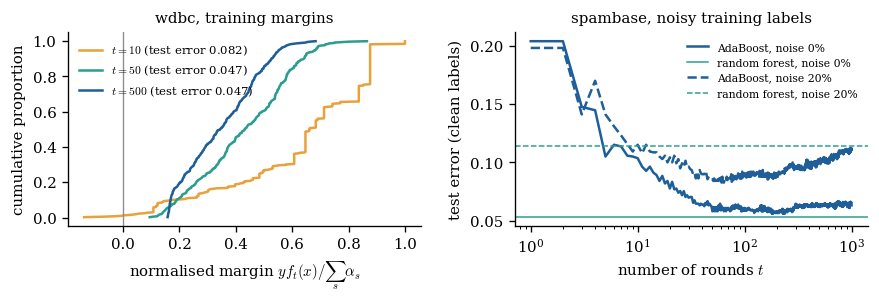

In [21]:
show_figure("tp3_margins_noise")

Between $t=50$ and $t=500$ the training error stays at $0$, but the distribution of the margins moves to the right: the smallest margin goes from $0.09$ to $0.16$. A vote with large margins is a *confident* vote: a small perturbation of the voters does not change its decisions, and margin-based generalization bounds (Section 15.6 and Schapire et al., 1998) decrease with the margins. This explains why the test error does not increase (no overfitting) although the vote keeps growing more complex, and why it can still decrease after the training error has reached $0$.

**3.** In terms of Section 15.6, $W_Q=\frac{1-M_Q}{2}$ is the weighted proportion of stumps that err. On the test set of `wdbc`:

In [22]:
show_table("p6_vote")

| vote | $t$ | risk of the vote | Gibbs risk | joint error $\hat e(Q)$ | $2\widehat{R}(G_Q)$ | $4\hat e(Q)$ |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| AdaBoost | 10 | 0.082 | 0.217 | 0.075 | 0.435 | 0.299 |
| AdaBoost | 100 | 0.041 | 0.322 | 0.113 | 0.644 | 0.451 |
| AdaBoost | 500 | 0.047 | 0.342 | 0.125 | 0.684 | 0.498 |
| random forest | 500 | 0.053 | 0.089 | 0.041 | 0.177 | 0.162 |

The vote of AdaBoost is excellent ($0.04$ to $0.05$), but its stumps are *weak*: their weighted Gibbs risk *increases* with $t$ (from $0.22$ to $0.34$), because AdaBoost keeps adding stumps that are only slightly better than random on the reweighted examples. The bounds of Section 15, which only use the mean ($2\widehat{R}(G_Q)\approx0.68$) or the second moment ($4\hat e(Q)\approx0.50$) of $W_Q$, are then far from the risk of the vote: $W_Q$ is spread between about $0.25$ and $0.45$ on most examples (small but positive margins), and Markov's inequality cannot see that it stays below $\frac12$. For the random forest, whose trees are individually good (Gibbs risk $0.09$) and diverse, the same quantities are much more informative ($4\hat e(Q)\approx0.16$). The guarantees of Part IV are well suited to votes of *good and diverse* voters, such as forests; for boosting, bounds based on the whole distribution of the margins (Schapire et al., 1998) are more appropriate.

**4.** Test error with clean labels after $100$ rounds, at its minimum, after $1000$ rounds, and of a random forest:

In [23]:
show_table("p6_noise")

| training noise | AdaBoost $t=100$ | AdaBoost best $t^\ast$ | AdaBoost $t=1000$ | random forest |
|:---:|:---:|:---:|:---:|:---:|
| 0\% | 0.061 | 0.056 | 0.063 | 0.053 |
| 20\% | 0.089 | 0.083 | 0.112 | 0.114 |

$^\ast$ selected on the test set, hence optimistic.

Without noise the test error of AdaBoost is stable. With $20\%$ of flipped labels it reaches a minimum ($0.083$) and then increases ($0.112$ at $t=1000$): the exponential loss gives an exponentially large weight to the examples with a negative margin, i.e. mostly to the mislabelled ones, which AdaBoost then tries to fit. Early stopping is necessary with noisy labels. The random forest of fully grown trees also suffers from the noise ($0.112$), since each tree fits it; limiting the depth or the size of the leaves would make it more robust.